# **A2-KOD GÖZLEMLERİNDE YANSIMA HATASI HESABI**

### **İş akışı özet:**

- **Satellites.csv okundu yine sat1den sat9 kadar gözlenen uydular ayrı listelere kaydedildi. 1-VERİLERİ OKUMA kısmı bitti.**
- **c,f1,f2, lambda1, lambda2 gibi değerler hesaplandı.**
- **P1 P2 farkı ve L1 L2 farkı hesaplandı. 2-TEMEL HESAPLAR kısmı bitti.**
- **<span style="color:red">N tamsayı belirsizliği nasıl hesaplanır? Hangi formülle? burada lamda çarpı N ile multipath hesabı nasıl yapılır?</span>**

## **1-VERİLERİ OKUMA**

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/satellites.csv")
df # pandas csv okumak için

,Satellite,C1,P1,L1,D1,P2,L2,D2
0,G19,2.118906e+07,2.118906e+07,-2.342237e+07,-1624.826,2.118906e+07,-1.823279e+07,-1266.095
1,G27,2.252061e+07,2.252061e+07,-1.626506e+07,-3131.943,2.252062e+07,-1.266448e+07,-2440.473
2,G11,2.096043e+07,2.096043e+07,-2.023690e+07,2125.069,2.096044e+07,-1.575303e+07,1655.895
3,G20,2.459961e+07,2.459961e+07,-4.001554e+06,3287.044,2.459962e+07,-2.858091e+06,2561.330
4,G22,2.234385e+07,2.234385e+07,-1.900831e+07,-2218.107,2.234386e+07,-1.478600e+07,-1728.398
5,G14,2.137030e+07,2.137029e+07,-1.900141e+07,-529.566,2.137030e+07,-1.455393e+07,-412.656
6,G32,2.112843e+07,2.112843e+07,-1.989570e+07,1824.349,2.112843e+07,-1.548879e+07,1421.562
7,G01,2.255605e+07,2.255605e+07,-1.514390e+07,2922.988,2.255606e+07,-1.177665e+07,2277.661
8,G31,0.000000e+00,2.520929e+07,-8.747164e+04,3119.319,2.522058e+07,-3.090521e+03,2429.440


In [3]:
# csvden yine listeye dönüştür sat1 sat2 ...
for i in range(9):
    globals()[f"sat{i+1}"] = ([str(df.iloc[i, 0])] + [float(x) for x in df.iloc[i, 1:]])
    print(globals()[f"sat{i+1}"])

['G19', 21189058.919, 21189058.224, -23422371.335, -1624.826, 21189062.761, -18232789.099, -1266.095]
['G27', 22520607.109, 22520607.184, -16265062.308, -3131.943, 22520615.61, -12664483.164, -2440.473]
['G11', 20960433.392, 20960432.985, -20236898.563, 2125.069, 20960438.054, -15753030.25, 1655.895]
['G20', 24599610.601, 24599611.385, -4001554.056, 3287.044, 24599619.779, -2858090.765, 2561.33]
['G22', 22343853.992, 22343853.46, -19008308.324, -2218.107, 22343856.607, -14786004.908, -1728.398]
['G14', 21370295.018, 21370294.498, -19001406.309, -529.566, 21370299.873, -14553929.347, -412.656]
['G32', 21128427.864, 21128427.325, -19895704.4, 1824.349, 21128433.745, -15488787.194, 1421.562]
['G01', 22556048.986, 22556050.48, -15143902.884, 2922.988, 22556058.525, -11776649.861, 2277.661]
['G31', 0.0, 25209285.799, -87471.641, 3119.319, 25220575.865, -3090.521, 2429.44]


## **2-TEMEL HESAPLAR**

### **Giriş**

- **GNSS sinyalleri uydudan alıcıya iki şekilde ulaşır doğrudan ve yansıyarak. Yansıtıcı yüzeylerden (bina, su vb.) gelen sinyaller alıcının hatalı ölçüm yapmasına sebep olur. Bu sinyal yansıma hatası (multipath error) olarak adlandırılır.**
- **Sözde menzil (Pseudorange) uydudan alıcıya gelen sinyalleri arada geçen zamanla çarparak bulunur. Sinyaller c=ışık hızında hareket eder. P=c.t**
- **GNSS Uydularından farklı dalga boylarında farklı bilgiler alınır. L1 ve L2 frekanslarında faz bilgileri ile P1 ve P2 kod bilgileri elde edilir. Kod bilgileri metre ile ifade edilir ve düşük hassasiyetli gözlemler yapılır. Faz bilgileri çevirim olarak saklanır ve metreye çevrilmelidir.**

### **Geometry Free Farklar**

 - **Kod gözlemlerinde mesafe + troposfer etkisi P1 ve P2 de aynıdır ama iyonosfer etkisi + multipath + gürültü farklıdır ikisi arasındaki farkı bu etkileri bize anlatır.**
 - **Fazdada iyonosfer + multipath + gürültü vardır ama faz üzerinde iyonosfer etkisi farklıdır.**
 - **Aynı zamanda taşıyıcı faz belirsizliği varsa cycle sliplerde faz gözlemleri üzerinde kalırlar.**
 - **İyonosferin birinci dereceden etkisi yaklaşık olarak frekansın karesiyle ters orantılıdır. L2 L1'den yaklaşık %65 daha fazla etkilenir.**

In [4]:
# ışık hızı m/s
c = 299792458  
# frekanslar Hz 
f1 = 1575.42 * 1000000
f2 = 1227.60 * 1000000
# lambda c/f metre/saniye / çevirim/saniye ==> metre/çevirim lambdanın birimi
lambda1 = c/f1
lambda2 = c/f2

In [5]:
lambda1, lambda2

(0.19029367279836487, 0.24421021342456825)

In [6]:
for i in range(9):
    sat_name = globals()[f"sat{i+1}"][0] #G0    
    sat_P1 = globals()[f"sat{i+1}"][2] #P1
    sat_P2 = globals()[f"sat{i+1}"][5] #P2
    GF = sat_P1 - sat_P2 # GF Geometry free kod kombinasyonu
    print(sat_name, GF)

G19 -4.537000000476837
G27 -8.425999999046326
G11 -5.069000001996756
G20 -8.393999997526407
G22 -3.1469999998807907
G14 -5.375
G32 -6.420000001788139
G01 -8.044999998062849
G31 -11290.065999999642


In [7]:
for i in range(9):
    sat_name = globals()[f"sat{i+1}"][0] #G0    
    sat_L1 = globals()[f"sat{i+1}"][3] #L1
    sat_L2 = globals()[f"sat{i+1}"][6] #L2
    GF = lambda1 * sat_L1 - lambda2 * sat_L2 # GF Geometry free faz kombinasyonu
    print(sat_name, GF)

G19 -4495.749792359769
G27 -2342.308491277974
G11 -3902.874165042769
G20 -63495.46250999626
G22 -6267.390378298238
G14 -61629.20287667494
G32 -3506.636852128431
G01 -5810.724316888489
G31 -15890.563038586926


## **3-YANSIMA HATASI**

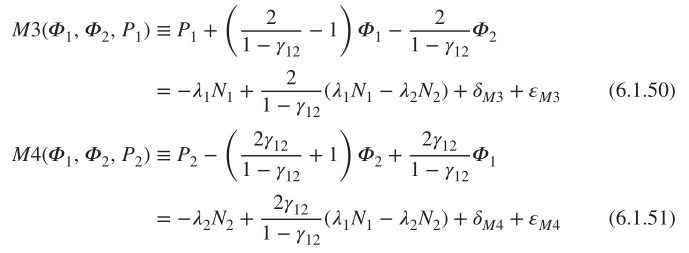

- **Yukarıda leick (Tek Kod – Çift Faz), aşağıda leick, xu xu, bernard hoffmann, (Melbourne-Wübbena / HMW).**

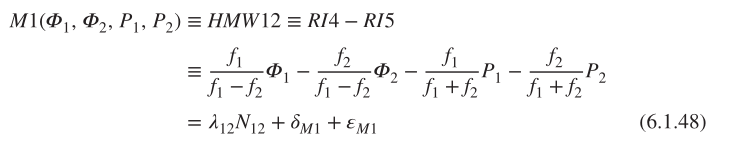

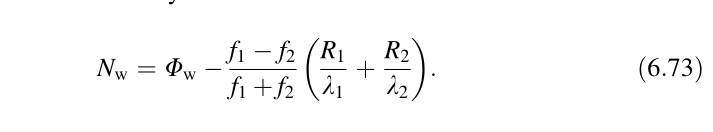

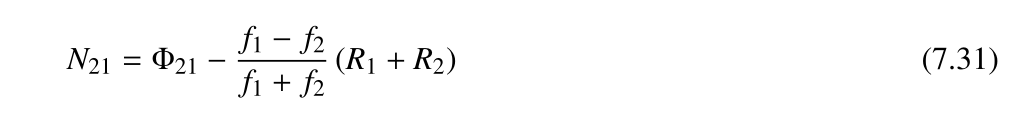

- **Aşağıda xu xu, bernard (Kod – Faz Farkı).**

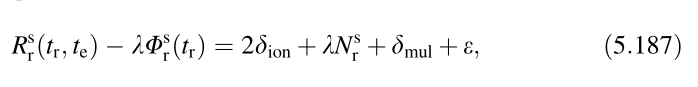

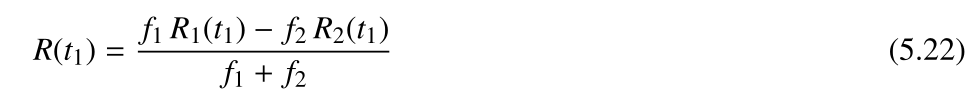

## **GNSSPY Multipath analizi <span style="color:red">(ÇOK BÜYÜK HATALAR VAR)</span>**

In [10]:
import gnsspy
file_path = "../data/ISTA2400.14o"
station = gnsspy.read_obsFile(file_path)
print(type(station))

Observation file  ../data/ISTA2400.14o  is read in 0.25 seconds.
<class 'gnsspy.io.io.Observation'>


In [11]:
from gnsspy.quality.multipath import multipath
result = multipath(station, system="G")
print(result[["Multipath1", "Multipath2"]].head(10))

                           Multipath1    Multipath2
SV  Epoch                                          
G01 2014-08-28 04:37:00 -6.810298e+06  8.880115e+06
    2014-08-28 04:37:30 -6.797339e+06  8.892308e+06
    2014-08-28 04:38:00 -6.774984e+06  8.920127e+06
    2014-08-28 04:39:30 -6.801790e+06 -1.653862e+07
    2014-08-28 04:40:00 -6.780913e+06 -1.651264e+07
    2014-08-28 04:40:30 -6.760407e+06 -1.648712e+07
    2014-08-28 04:54:00 -6.809199e+06 -1.654784e+07
    2014-08-28 04:54:30 -6.799470e+06 -1.653573e+07
    2014-08-28 04:55:00 -6.790152e+06 -1.652414e+07
    2014-08-28 05:00:00 -6.813952e+06 -1.655375e+07


In [12]:
# Benim epoğum
epoch_time = pd.Timestamp("2014-08-28 17:15:00")
start_time = epoch_time - pd.Timedelta(minutes=1)
end_time = epoch_time + pd.Timedelta(minutes=1)

# İndeks filtrele eopğuma göre
epochs = result.index.get_level_values("Epoch")
selected = result.loc[
    (epochs >= start_time) & (epochs <= end_time),
    ["Multipath1", "Multipath2"]
]
print(selected)

                           Multipath1     Multipath2
SV  Epoch                                           
G01 2014-08-28 17:14:00 -2.798722e+05 -312529.267794
    2014-08-28 17:14:30 -2.798725e+05 -312529.827437
    2014-08-28 17:15:00 -2.798726e+05 -312529.499303
    2014-08-28 17:15:30 -2.798721e+05 -312529.164144
    2014-08-28 17:16:00 -2.798718e+05 -312529.367800
G11 2014-08-28 17:14:00 -1.620875e+05 -264049.172852
    2014-08-28 17:14:30 -1.620877e+05 -264049.060708
    2014-08-28 17:15:00 -1.620877e+05 -264048.943855
    2014-08-28 17:15:30 -1.620877e+05 -264048.894651
    2014-08-28 17:16:00 -1.620879e+05 -264048.986825
G14 2014-08-28 17:14:00  4.426841e+04  -76256.442565
    2014-08-28 17:14:30  4.426855e+04  -76256.316616
    2014-08-28 17:15:00  4.426843e+04  -76256.400710
    2014-08-28 17:15:30  4.426820e+04  -76256.425672
    2014-08-28 17:16:00  4.426825e+04  -76256.315249
G19 2014-08-28 17:14:00  3.132370e+05  137908.089407
    2014-08-28 17:14:30  3.132368e+05  137907.